Load and check duplicates


In [1]:
import pandas as pd
import numpy as np

df = pd.read_parquet("../data/raw/online_retail_II.parquet")
print(df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print(df.isna().mean().round(3))
print(df.describe(include="all").T[["count", "min", "max"]])

(1067371, 8)
Exact duplicate rows: 34335
Invoice        0.000
StockCode      0.000
Description    0.004
Quantity       0.000
InvoiceDate    0.000
Price          0.000
Customer ID    0.228
Country        0.000
dtype: float64
                 count                  min                  max
Invoice        1067371                  NaN                  NaN
StockCode      1067371                  NaN                  NaN
Description    1062989                  NaN                  NaN
Quantity     1067371.0             -80995.0              80995.0
InvoiceDate    1067371  2009-12-01 07:45:00  2011-12-09 12:50:00
Price        1067371.0            -53594.36              38970.0
Customer ID   824364.0              12346.0              18287.0
Country        1067371                  NaN                  NaN


Understand the dirty rows before dropping them

In [2]:
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)

cancels = df["Invoice"].str.startswith("C")
print("Cancellation rows:", cancels.sum())
print("Qty <= 0 (non-cancel):", ((df["Quantity"] <= 0) & ~cancels).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())

# Non-product codes (postage, fees, adjustments, etc.)
non_product = df[~df["StockCode"].str.match(r"^\d{5}")]["StockCode"].value_counts()
print(non_product.head(20))

Cancellation rows: 19494
Qty <= 0 (non-cancel): 3457
Price <= 0: 6207
StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
gift_0001_10      16
CRUK              16
DCGS0076          15
TEST001           15
DCGS0003          14
Name: count, dtype: int64


Clean

In [3]:
clean = df.drop_duplicates().copy()

clean = clean[~clean["Invoice"].str.startswith("C")]     # cancellations
clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)]
clean = clean[clean["StockCode"].str.match(r"^\d{5}")]   # real products only

clean["Description"] = clean["Description"].str.strip().str.upper()
clean["Revenue"] = clean["Quantity"] * clean["Price"]
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"])
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
clean["Week"] = clean["InvoiceDate"].dt.to_period("W").dt.start_time

print(df.shape, "->", clean.shape)
print("Rows kept: {:.1%}".format(len(clean) / len(df)))

(1067371, 8) -> (1003214, 11)
Rows kept: 94.0%


Quick EDA

Matplotlib is building the font cache; this may take a moment.


StockCode  Description                        
22423      REGENCY CAKESTAND 3 TIER               330590.32
85123A     WHITE HANGING HEART T-LIGHT HOLDER     257546.20
23843      PAPER CRAFT , LITTLE BIRDIE            168469.60
47566      PARTY BUNTING                          148318.28
85099B     JUMBO BAG RED RETROSPOT                145961.83
84879      ASSORTED COLOUR BIRD ORNAMENT          129324.49
22086      PAPER CHAIN KIT 50'S CHRISTMAS         117760.29
23166      MEDIUM CERAMIC TOP STORAGE JAR          81700.92
79321      CHILLI LIGHTS                           80540.88
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     71300.40
Name: Revenue, dtype: float64
           nunique          min          max        count       spread
count  4878.000000  4878.000000  4878.000000  4878.000000  4878.000000
mean      4.447724     2.844340     7.543665   205.660927     5.060364
std       2.502989     5.528457    22.251249   335.780152    48.061417
min       1.000000     0.030000     0.0

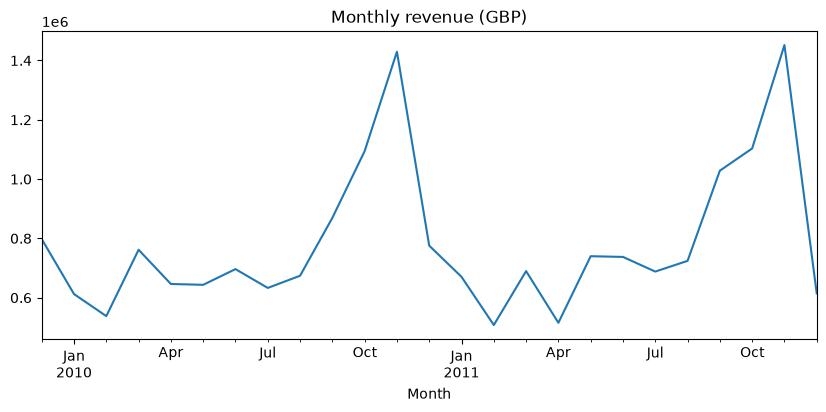

In [4]:
# 1. Revenue over time
clean.groupby("Month")["Revenue"].sum().plot(figsize=(10, 4), title="Monthly revenue (GBP)")

# 2. Top 10 products by revenue
print(clean.groupby(["StockCode", "Description"])["Revenue"].sum().nlargest(10))

# 3. How much does price actually vary per product? (key for elasticity)
price_var = clean.groupby("StockCode")["Price"].agg(["nunique", "min", "max", "count"])
price_var["spread"] = price_var["max"] / price_var["min"]
print(price_var.describe())
print("Products with 3+ distinct prices:", (price_var["nunique"] >= 3).sum())

Check and handle quantity outliers

In [6]:
#clean = pd.read_parquet("../data/processed_clean.parquet")  # skip if still in memory

print(clean["Quantity"].describe(percentiles=[.5, .9, .99, .999]))
print(clean.nlargest(10, "Quantity")[["Invoice", "StockCode", "Description", "Quantity", "Price", "InvoiceDate"]])
print(clean.nlargest(5, "Price")[["StockCode", "Description", "Quantity", "Price"]])

count    1.003214e+06
mean     1.115193e+01
std      1.287471e+02
min      1.000000e+00
50%      4.000000e+00
90%      2.400000e+01
99%      1.080000e+02
99.9%    5.000000e+02
max      8.099500e+04
Name: Quantity, dtype: float64
        Invoice StockCode                         Description  Quantity  \
1065882  581483     23843         PAPER CRAFT , LITTLE BIRDIE     80995   
587080   541431     23166      MEDIUM CERAMIC TOP STORAGE JAR     74215   
90857    497946     37410  BLACK AND WHITE PAISLEY FLOWER MUG     19152   
127166   501534     21099         SET/6 STRAWBERRY PAPER CUPS     12960   
127168   501534     21091         SET/6 WOODLAND PAPER PLATES     12960   
127169   501534     21085           SET/6 WOODLAND PAPER CUPS     12744   
127167   501534     21092       SET/6 STRAWBERRY PAPER PLATES     12480   
135027   502269     21984     PACK OF 12 PINK PAISLEY TISSUES     10000   
135028   502269     21982             PACK OF 12 SUKI TISSUES     10000   
135029   502269     2

Save

In [ ]:
q_cap = clean["Quantity"].quantile(0.999)
print("99.9th pct quantity:", q_cap)

before = len(clean)
clean = clean[clean["Quantity"] <= q_cap].copy()
print("Dropped", before - len(clean), "extreme-quantity rows")

clean.to_parquet("../data/processed_clean.parquet", index=False)

99.9th pct quantity: 500.0
Dropped 948 extreme-quantity rows
